<a href="https://colab.research.google.com/github/sreeramchennakrish/MIDS-281-project/blob/main/notebooks/06_classifier_resnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. ResNet vs handcrafted features

Parul. Same train/val images as the SVM in `04_classifier_svm.ipynb` (paths stored in `combined_weighted_features.npz`). Official `Test` folder is held out and scored once. Architecture and 224-crop follow `fire_flame_.ipynb`, but that notebook trained on the full Train folder and used Test inside the training loop, so it is not a fair comparison. This notebook uses ImageNet-pretrained ResNet-50 and standard backprop (no torchfusion).


In [1]:
# Colab setup
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install numpy pandas matplotlib scikit-learn torch torchvision
    if not os.path.exists("/content/MIDS-281-project/.git"):
        !git clone --depth 1 https://github.com/sreeramchennakrish/MIDS-281-project.git /content/MIDS-281-project
    %cd /content/MIDS-281-project/notebooks

print("cwd:", os.getcwd())

Cloning into '/content/MIDS-281-project'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 28 (delta 1), reused 21 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 149.25 MiB | 137.32 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/MIDS-281-project/notebooks
cwd: /content/MIDS-281-project/notebooks


## Load split and images

In [2]:
import zipfile
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet50_Weights
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
)

FEATURE_DIR = Path("../features").resolve()
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET").resolve()
MODEL_DIR = Path("../models/resnet").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ZIP_URL = "https://github.com/DeepQuestAI/Fire-Smoke-Dataset/releases/download/v1/FIRE-SMOKE-DATASET.zip"
ZIP_PATH = DATA_DIR.parent / "FIRE-SMOKE-DATASET.zip"

if not (DATA_DIR / "Train" / "Fire").exists():
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    if not ZIP_PATH.exists():
        print("Downloading dataset...")
        urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)
    print("Unzipping...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR.parent)

TRAIN_DIR = DATA_DIR / "Train"
TEST_DIR = DATA_DIR / "Test"
print("Train:", TRAIN_DIR.exists(), "Test:", TEST_DIR.exists())

with np.load(FEATURE_DIR / "combined_weighted_features.npz") as data:
    y_train = data["y_train"]
    y_val = data["y_val"]
    train_paths = data["train_paths"]
    val_paths = data["val_paths"]
    classes = np.asarray(data["classes"])

print("Train images:", len(train_paths), "Val images:", len(val_paths))
print("Classes:", classes)
print("Train counts:", dict(Counter(y_train.tolist())))
print("Val counts:", dict(Counter(y_val.tolist())))

Unzipping...
Train: True Test: True
Train images: 2160 Val images: 541
Classes: ['Fire' 'Smoke' 'Neutral']
Train counts: {1: 720, 2: 720, 0: 720}
Val counts: {0: 180, 1: 180, 2: 181}


In [3]:
def resolve_saved_path(saved, data_dir=DATA_DIR):
    """Map teammate absolute paths onto this machine. Checkpoint files map to the real jpg."""
    p = Path(str(saved))
    name = p.name.replace("-checkpoint", "")
    parts = list(p.parts)
    if ".ipynb_checkpoints" in parts:
        cls = p.parent.parent.name  # Fire / Smoke / Neutral
        split = p.parent.parent.parent.name  # Train
        local = data_dir / split / cls / name
    else:
        try:
            rel = Path(*parts[parts.index("FIRE-SMOKE-DATASET") + 1 : -1]) / name
        except ValueError:
            rel = Path(p.parent.parent.name) / p.parent.name / name
        local = data_dir / rel
    if not local.exists():
        raise FileNotFoundError(f"{saved} -> {local}")
    return local


train_files = [resolve_saved_path(p) for p in train_paths]
val_files = [resolve_saved_path(p) for p in val_paths]

test_files, test_labels = [], []
extensions = {".jpg", ".jpeg", ".png"}
for label, cls in enumerate(classes):
    folder = TEST_DIR / cls
    for path in sorted(folder.rglob("*")):
        if path.suffix.lower() in extensions:
            test_files.append(path)
            test_labels.append(label)
y_test = np.asarray(test_labels)

print("Resolved train/val/test:", len(train_files), len(val_files), len(test_files))
print("Test counts:", dict(Counter(y_test.tolist())))
overlap = set(p.name for p in val_files) & set(p.name for p in train_files)
print("Filename overlap train vs val:", len(overlap))

Resolved train/val/test: 2160 541 300
Test counts: {0: 100, 1: 100, 2: 100}
Filename overlap train vs val: 438


## Dataset and ResNet-50

In [4]:
class PathListDataset(Dataset):
    def __init__(self, files, labels, transform):
        self.files = list(files)
        self.labels = np.asarray(labels)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])


# Same crop size as fire_flame_.ipynb. ImageNet stats because we start from ImageNet weights.
imagenet = ResNet50_Weights.IMAGENET1K_V1
train_tf = transforms.Compose([
    transforms.Resize(225),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_tf = train_tf

batch_size = 32
train_loader = DataLoader(PathListDataset(train_files, y_train, train_tf), batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(PathListDataset(val_files, y_val, eval_tf), batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(PathListDataset(test_files, y_test, eval_tf), batch_size=batch_size, shuffle=False, num_workers=0)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

model = models.resnet50(weights=imagenet)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
print(model.fc)

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 240MB/s]


Linear(in_features=2048, out_features=3, bias=True)


## Train on the SVM train split, pick checkpoint on val

epoch 1/8  train_loss=0.2319 train_acc=0.9190  val_loss=0.0666 val_acc=0.9760
  saved /content/MIDS-281-project/models/resnet/resnet50_same_split.pt
epoch 2/8  train_loss=0.0566 train_acc=0.9852  val_loss=0.1265 val_acc=0.9575
epoch 3/8  train_loss=0.0306 train_acc=0.9917  val_loss=0.0787 val_acc=0.9778
  saved /content/MIDS-281-project/models/resnet/resnet50_same_split.pt
epoch 4/8  train_loss=0.0096 train_acc=0.9963  val_loss=0.0905 val_acc=0.9760
epoch 5/8  train_loss=0.0080 train_acc=0.9977  val_loss=0.1320 val_acc=0.9704
epoch 6/8  train_loss=0.0172 train_acc=0.9944  val_loss=0.1647 val_acc=0.9649
epoch 7/8  train_loss=0.0556 train_acc=0.9810  val_loss=0.1348 val_acc=0.9630
epoch 8/8  train_loss=0.0243 train_acc=0.9912  val_loss=0.1758 val_acc=0.9538


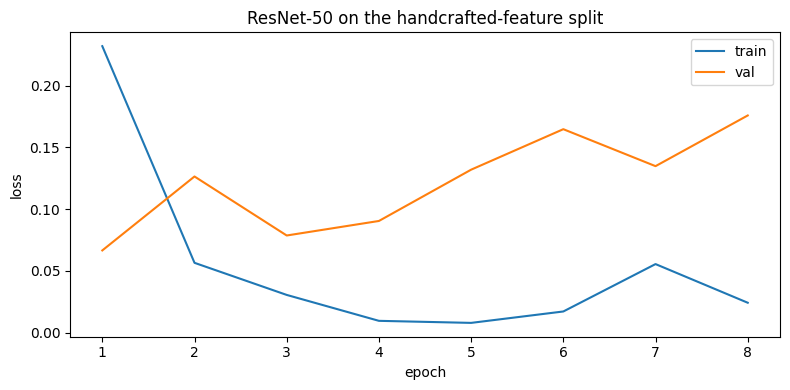

In [5]:
def run_epoch(loader, train=True):
    model.train(train)
    total_loss, n = 0.0, 0
    preds, ys = [], []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            n += y.size(0)
            pred = logits.argmax(1)
            preds.append(pred.detach().cpu().numpy())
            ys.append(y.detach().cpu().numpy())
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(preds)
    return total_loss / n, accuracy_score(y_true, y_pred), y_true, y_pred


n_epochs = 8
best_val = -1.0
ckpt = MODEL_DIR / "resnet50_same_split.pt"
history = []

for epoch in range(1, n_epochs + 1):
    tr_loss, tr_acc, _, _ = run_epoch(train_loader, train=True)
    va_loss, va_acc, _, _ = run_epoch(val_loader, train=False)
    history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc})
    print(f"epoch {epoch}/{n_epochs}  train_loss={tr_loss:.4f} train_acc={tr_acc:.4f}  val_loss={va_loss:.4f} val_acc={va_acc:.4f}")
    if va_acc > best_val:
        best_val = va_acc
        torch.save({"model": model.state_dict(), "val_acc": best_val, "epoch": epoch}, ckpt)
        print("  saved", ckpt)

hist = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(hist["epoch"], hist["train_loss"], label="train")
plt.plot(hist["epoch"], hist["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("ResNet-50 on the handcrafted-feature split")
plt.tight_layout()
plt.show()

## Val and Test scores

Loaded epoch 3 val_acc 0.977818853974122
ResNet-50 (val, same split as SVM)
Accuracy: 0.977818853974122
              precision    recall  f1-score   support

        Fire       1.00      0.95      0.97       180
       Smoke       0.94      0.99      0.97       180
     Neutral       0.99      0.99      0.99       181

    accuracy                           0.98       541
   macro avg       0.98      0.98      0.98       541
weighted avg       0.98      0.98      0.98       541



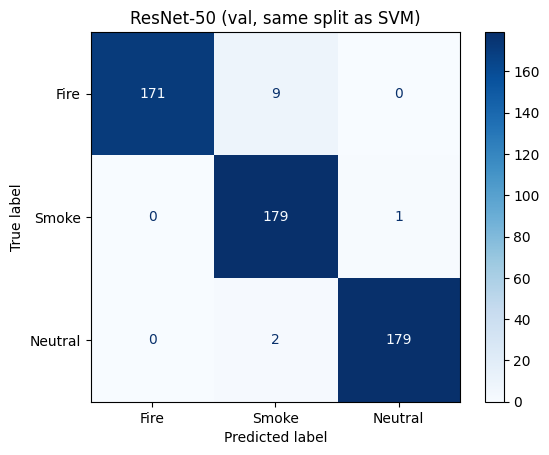

ResNet-50 (official Test, not used in training)
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

        Fire       0.98      0.93      0.95       100
       Smoke       0.95      0.98      0.97       100
     Neutral       0.97      0.99      0.98       100

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



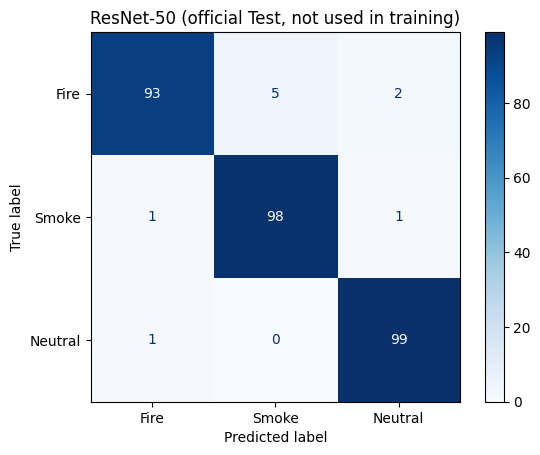

,Model,Accuracy,Precision,Recall,F1 Score
0,"ResNet-50 (val, same split as SVM)",0.9778,0.9788,0.9778,0.9779
1,"ResNet-50 (official Test, not used in training)",0.9667,0.9670,0.9667,0.9665
2,"SVM combined 8206-d (val, notebook 04)",0.8262,0.8298,0.8262,0.8260


SVM Test is still empty until someone extracts 8206-d features on Test.
Do not tune after looking at Test.


In [6]:
blob = torch.load(ckpt, map_location=device)
model.load_state_dict(blob["model"])
print("Loaded epoch", blob["epoch"], "val_acc", blob["val_acc"])


def report(name, y_true, y_pred):
    print("=" * 60)
    print(name)
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred, target_names=classes))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=classes, cmap="Blues")
    plt.title(name)
    plt.show()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1 Score": f1_score(y_true, y_pred, average="macro"),
    }


_, _, yv, pv = run_epoch(val_loader, train=False)
_, _, yt, pt = run_epoch(test_loader, train=False)
rows = [
    report("ResNet-50 (val, same split as SVM)", yv, pv),
    report("ResNet-50 (official Test, not used in training)", yt, pt),
    {
        "Model": "SVM combined 8206-d (val, notebook 04)",
        "Accuracy": 0.8262,
        "Precision": 0.8298,
        "Recall": 0.8262,
        "F1 Score": 0.8260,
    },
]
comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))
print("SVM Test is still empty until someone extracts 8206-d features on Test.")
print("Do not tune after looking at Test.")